In [ ]:
# ==========================================
# 1. Import libraries
# ==========================================

import pandas as pd
import re

# ==========================================
# 2. Upload dataset
# ==========================================

from google.colab import files
uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded")
print(df.columns)

# ==========================================
# 3. Extract variants from genotype column
# ==========================================

rows = []

for _, r in df.iterrows():

    variants = str(r["Predicted protein change"]).split(";")

    for v in variants:

        v = v.strip()

        if v.startswith("p."):
            rows.append({
                "variant": v,
                "region": r["Final_Class"]
            })

variants_df = pd.DataFrame(rows)

# ==========================================
# 4. Count mutations per region
# ==========================================

region_counts = variants_df["region"].value_counts()

print("\nMutation counts per functional region:\n")
print(region_counts)

# ==========================================
# 5. Optional: table format
# ==========================================

region_table = region_counts.reset_index()
region_table.columns = ["Region", "Mutation_Count"]

print("\nMutation count table:")
print(region_table)

Saving Burgmaier_Genotype_Phenotype_Replication - Data for Visualization (6).csv to Burgmaier_Genotype_Phenotype_Replication - Data for Visualization (6).csv
Dataset loaded
Index(['Age at ARPKD diagnosis (yrs)',
       'Kidney cysts/ enlarge- ment at diagnosis', 'KRT (age at onset, yrs)',
       'Portal HTN during disease course (age, yrs)',
       'Substan- tial hepatic compli- cation during disease course (age, yrs)',
       'Last follow- up (age, yrs), Death', 'RSA', 'FoldX',
       'Predicted protein change', 'Functional class', 'Final_Class'],
      dtype='object')

Mutation counts per functional region:

region
AA709-1837     102
AA1-708         88
AA1838-2624     44
AA2625-4074     42
Name: count, dtype: int64

Mutation count table:
        Region  Mutation_Count
0   AA709-1837             102
1      AA1-708              88
2  AA1838-2624              44
3  AA2625-4074              42


In [ ]:
region_lengths = {
"AA1-708":708,
"AA709-1837":1129,
"AA1838-2624":787,
"AA2625-4074":1450
}

region_table["Length"] = region_table["Region"].map(region_lengths)

region_table["Mutations_per_AA"] = region_table["Mutation_Count"] / region_table["Length"]

print(region_table)

# Patient counts per functional region
patient_counts = df["Final_Class"].value_counts()

print("\nPatient counts per functional region:\n")
print(patient_counts)

        Region  Mutation_Count  Length  Mutations_per_AA
0   AA709-1837             102    1129          0.090345
1      AA1-708              88     708          0.124294
2  AA1838-2624              44     787          0.055909
3  AA2625-4074              42    1450          0.028966

Patient counts per functional region:

Final_Class
AA709-1837     51
AA1-708        44
AA1838-2624    22
AA2625-4074    21
Name: count, dtype: int64


In [ ]:
# ==========================================
# Extract MISSENSE substitutions only
# ==========================================

import re

aa3_to_aa1 = {
    "Ala":"A","Arg":"R","Asn":"N","Asp":"D","Cys":"C",
    "Gln":"Q","Glu":"E","Gly":"G","His":"H","Ile":"I",
    "Leu":"L","Lys":"K","Met":"M","Phe":"F","Pro":"P",
    "Ser":"S","Thr":"T","Trp":"W","Tyr":"Y","Val":"V"
}

rows = []

for _, r in df.iterrows():

    variants = str(r["Predicted protein change"]).split(";")

    for v in variants:

        v = v.strip()

        # match missense only (no *, no frameshift)
        m = re.match(r"p\.([A-Za-z]{3})(\d+)([A-Za-z]{3})$", v)

        if m:

            wt3 = m.group(1)
            mut3 = m.group(3)

            wt = aa3_to_aa1.get(wt3)
            mut = aa3_to_aa1.get(mut3)

            substitution = f"{wt}->{mut}"

            rows.append({
                "variant": v,
                "region": r["Final_Class"],
                "substitution": substitution
            })

variants_df = pd.DataFrame(rows)

print("Missense variants extracted:")
print(variants_df.head())

Missense variants extracted:
        variant       region substitution
0   p.Ile222Val      AA1-708         I->V
1    p.Thr36Met      AA1-708         T->M
2  p.Arg2370Gly  AA1838-2624         R->G
3  p.Ile2851Thr  AA2625-4074         I->T
4  p.Ile2851Thr  AA2625-4074         I->T


In [ ]:
sub_by_region = pd.crosstab(
    variants_df["substitution"],
    variants_df["region"]
)

print("\nMissense substitution frequencies by region:\n")
print(sub_by_region)



Missense substitution frequencies by region:

region        AA1-708  AA1838-2624  AA2625-4074  AA709-1837
substitution                                               
A->E                0            0            0           1
A->V                0            0            0           1
C->F                0            0            0           1
C->G                0            5            0           0
C->Y                0            0            0          11
D->N                0            2            0           0
D->V                0            0            1           0
F->C                0            1            0           0
F->L                7            0            0           4
G->C                0            0            2           0
G->D                0            2            0           0
G->E                0            0            1           0
G->R                1            0            2           2
G->S                1            0            0      

In [ ]:
print("\nOverall substitution frequencies:\n")
print(variants_df["substitution"].value_counts())


Overall substitution frequencies:

substitution
T->M    29
R->W    19
I->T    17
F->L    11
C->Y    11
R->C     8
I->V     8
S->L     6
I->K     6
P->L     5
H->Y     5
P->S     5
C->G     5
G->R     5
I->S     4
R->G     3
V->L     3
L->P     2
I->L     2
G->D     2
M->K     2
G->C     2
L->S     2
V->A     2
G->S     2
D->N     2
Y->C     2
L->R     2
F->C     1
V->D     1
Y->H     1
G->E     1
I->F     1
W->R     1
N->T     1
D->V     1
A->E     1
R->K     1
A->V     1
S->C     1
T->A     1
C->F     1
W->C     1
R->L     1
R->Q     1
Name: count, dtype: int64


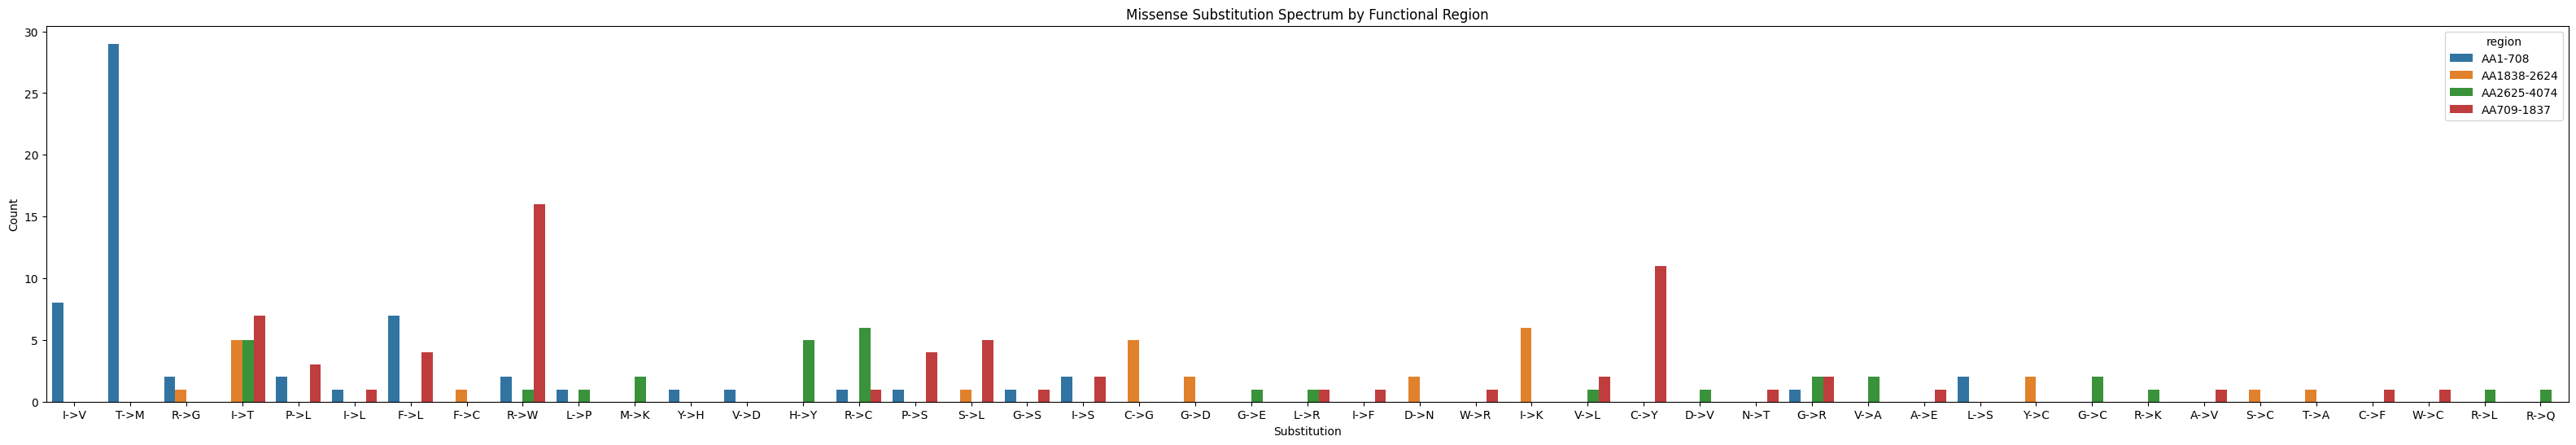

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(40,6))

sns.countplot(
    data=variants_df,
    x="substitution",
    hue="region"
)

plt.title("Missense Substitution Spectrum by Functional Region")
plt.ylabel("Count")
plt.xlabel("Substitution")

plt.show()

In [ ]:
# ==========================================================
# 1. Import libraries
# ==========================================================

import pandas as pd
import re
from scipy.stats import chi2_contingency
from google.colab import files

# ==========================================================
# 2. Upload dataset
# ==========================================================

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded")
print(df.columns)

# ==========================================================
# 3. Amino acid conversion (3-letter → 1-letter)
# ==========================================================

aa3_to_aa1 = {
    "Ala":"A","Arg":"R","Asn":"N","Asp":"D","Cys":"C",
    "Gln":"Q","Glu":"E","Gly":"G","His":"H","Ile":"I",
    "Leu":"L","Lys":"K","Met":"M","Phe":"F","Pro":"P",
    "Ser":"S","Thr":"T","Trp":"W","Tyr":"Y","Val":"V"
}

# ==========================================================
# 4. Extract MISSENSE variants only
# ==========================================================

rows = []

for _, r in df.iterrows():

    variants = str(r["Predicted protein change"]).split(";")

    for v in variants:

        v = v.strip()

        # match missense only
        m = re.match(r"p\.([A-Za-z]{3})(\d+)([A-Za-z]{3})$", v)

        if m:

            wt3 = m.group(1)
            mut3 = m.group(3)

            wt = aa3_to_aa1.get(wt3)
            mut = aa3_to_aa1.get(mut3)

            rows.append({
                "variant": v,
                "wt": wt,
                "mut": mut,
                "region": r["Final_Class"]
            })

variants_df = pd.DataFrame(rows)

print("\nExtracted missense variants:")
print(variants_df.head())

# ==========================================================
# 5. Filter mutations occurring on G, P, R residues
# ==========================================================

subset = variants_df[variants_df["wt"].isin(["G","P","R"])]

print("\nSubset of mutations on G, P, R:")
print(subset.head())

# ==========================================================
# 6. Build contingency table (Residue × Region)
# ==========================================================

table = pd.crosstab(subset["wt"], subset["region"])

print("\nContingency table (Residue × Region):\n")
print(table)

# ==========================================================
# 7. Chi-square test of independence
# ==========================================================

chi2, p, dof, expected = chi2_contingency(table)

print("\nChi-square test results:")
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)

# ==========================================================
# 8. Show expected counts
# ==========================================================

expected_df = pd.DataFrame(
    expected,
    index=table.index,
    columns=table.columns
)

print("\nExpected frequencies:")
print(expected_df)

# ==========================================================
# 9. Interpretation
# ==========================================================

if p < 0.05:
    print("\nResult: Mutation frequency on G, P, R differs significantly across functional regions.")
else:
    print("\nResult: No significant difference in mutation distribution across regions.")

Saving Burgmaier_Genotype_Phenotype_Replication - Data for Visualization (6).csv to Burgmaier_Genotype_Phenotype_Replication - Data for Visualization (6) (2).csv
Dataset loaded
Index(['Age at ARPKD diagnosis (yrs)',
       'Kidney cysts/ enlarge- ment at diagnosis', 'KRT (age at onset, yrs)',
       'Portal HTN during disease course (age, yrs)',
       'Substan- tial hepatic compli- cation during disease course (age, yrs)',
       'Last follow- up (age, yrs), Death', 'RSA', 'FoldX',
       'Predicted protein change', 'Functional class', 'Final_Class'],
      dtype='object')

Extracted missense variants:
        variant wt mut       region
0   p.Ile222Val  I   V      AA1-708
1    p.Thr36Met  T   M      AA1-708
2  p.Arg2370Gly  R   G  AA1838-2624
3  p.Ile2851Thr  I   T  AA2625-4074
4  p.Ile2851Thr  I   T  AA2625-4074

Subset of mutations on G, P, R:
         variant wt mut       region
2   p.Arg2370Gly  R   G  AA1838-2624
5    p.Pro755Leu  P   L   AA709-1837
13  p.Arg1624Trp  R   W   AA7

# **Check Burgmaier analysis without R1624W**

Saving Burgmaier_Genotype_Phenotype_Replication - Data for Visualization (6).csv to Burgmaier_Genotype_Phenotype_Replication - Data for Visualization (6) (5).csv
Dataset loaded
Index(['Age at ARPKD diagnosis (yrs)',
       'Kidney cysts/ enlarge- ment at diagnosis', 'KRT (age at onset, yrs)',
       'Portal HTN during disease course (age, yrs)',
       'Substan- tial hepatic compli- cation during disease course (age, yrs)',
       'Last follow- up (age, yrs), Death', 'RSA', 'FoldX',
       'Predicted protein change', 'Functional class', 'Final_Class'],
      dtype='object')
Initial sample size: 136
Patients with R1624W: 12
Sample size after removal: 124


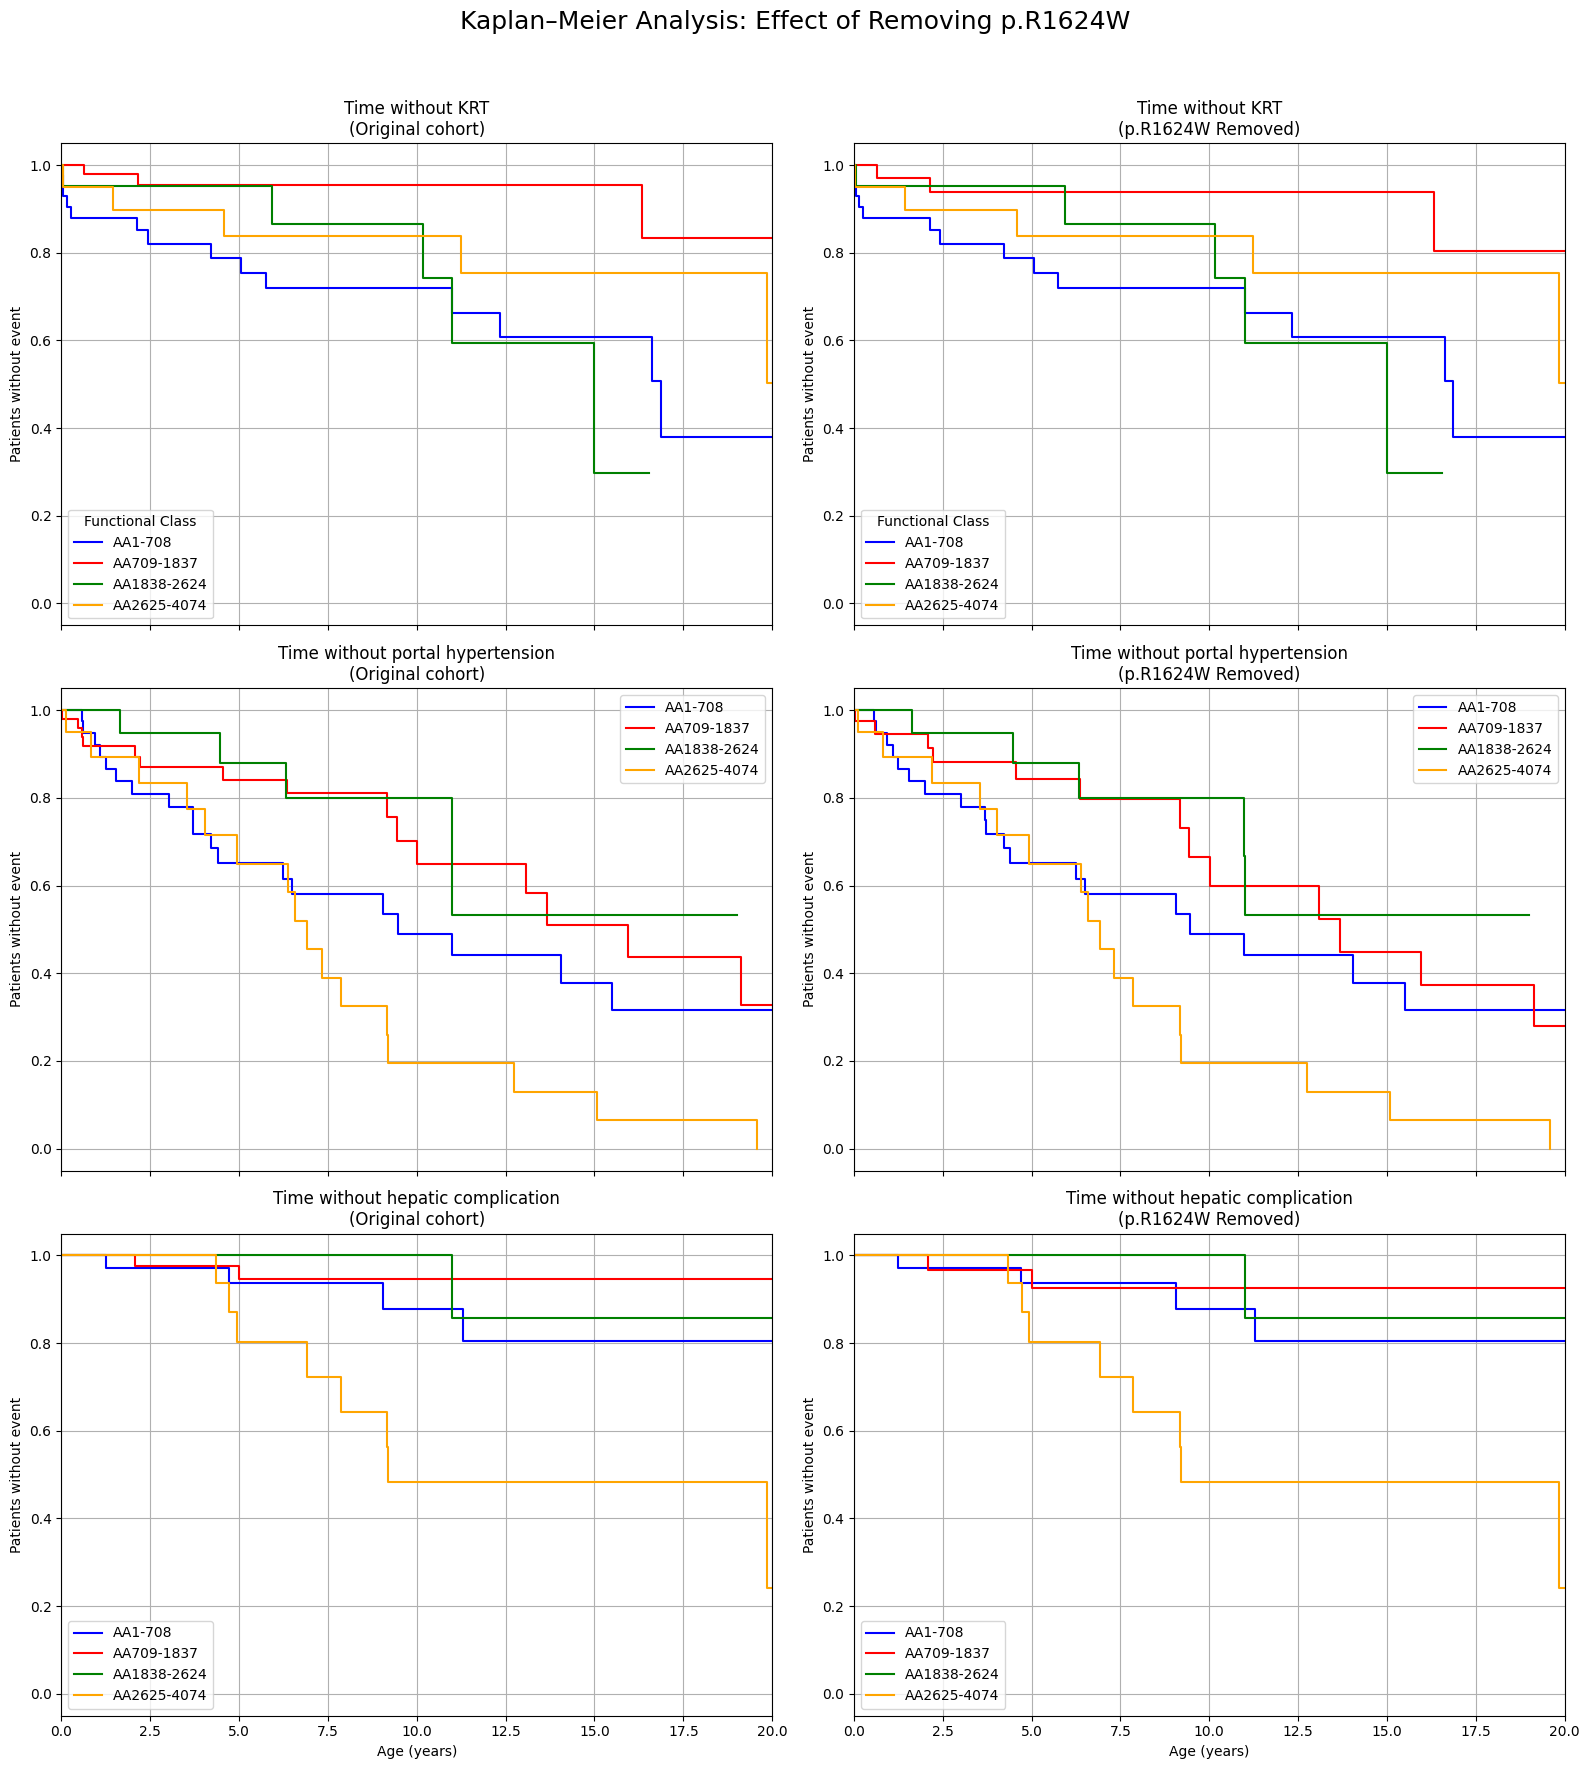

In [ ]:
# ==========================================================
# Install package
# ==========================================================

!pip install lifelines

# ==========================================================
# Import libraries
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from google.colab import files

# ==========================================================
# Upload dataset
# ==========================================================

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded")
print(df.columns)

# ==========================================================
# Rename columns
# ==========================================================

df = df.rename(columns={
    "KRT (age at onset, yrs)": "KRT_age",
    "Portal HTN during disease course (age, yrs)": "Portal_HTN_age",
    "Substan- tial hepatic compli- cation during disease course (age, yrs)": "Hepatic_complication_age",
    "Last follow- up (age, yrs), Death": "Last_followup_age",
    "Final_Class": "Functional_Class"
})

# ==========================================================
# Clean data
# ==========================================================

cols = [
    "KRT_age",
    "Portal_HTN_age",
    "Hepatic_complication_age",
    "Last_followup_age"
]

df[cols] = (
    df[cols]
    .replace(['-', '#ERROR!'], np.nan)
    .apply(pd.to_numeric, errors='coerce')
)

df = df.dropna(subset=["Functional_Class","Last_followup_age"])

print("Initial sample size:", len(df))

# ==========================================================
# Create filtered dataset without R1624W
# ==========================================================

mask = df["Predicted protein change"].str.contains("Arg1624Trp", na=False)

print("Patients with R1624W:", mask.sum())

df_no_R1624 = df[~mask].copy()

print("Sample size after removal:", len(df_no_R1624))

# ==========================================================
# Kaplan–Meier setup
# ==========================================================

events = {
    "KRT_age":"Time without KRT",
    "Portal_HTN_age":"Time without portal hypertension",
    "Hepatic_complication_age":"Time without hepatic complication"
}

groups = [
    "AA1-708",
    "AA709-1837",
    "AA1838-2624",
    "AA2625-4074"
]

color_map = {
    "AA1-708":"blue",
    "AA709-1837":"red",
    "AA1838-2624":"green",
    "AA2625-4074":"orange"
}

kmf = KaplanMeierFitter()

# ==========================================================
# Plot side-by-side comparison
# ==========================================================

fig, axes = plt.subplots(3,2,figsize=(16,18),sharex=True)

datasets = {
    "Original cohort": df,
    "p.R1624W Removed": df_no_R1624
}

for col_idx,(dataset_name,data) in enumerate(datasets.items()):

    for row_idx,(event_col,title) in enumerate(events.items()):

        ax = axes[row_idx,col_idx]

        for g in groups:

            gdf = data[data["Functional_Class"] == g].copy()

            if gdf.empty:
                continue

            gdf["time"] = gdf[event_col].fillna(gdf["Last_followup_age"])
            gdf["event"] = gdf[event_col].notna().astype(int)

            gdf = gdf.dropna(subset=["time"])

            kmf.fit(
                durations=gdf["time"],
                event_observed=gdf["event"],
                label=g
            )

            kmf.plot(
                ax=ax,
                ci_show=False,
                color=color_map[g]
            )

        ax.set_title(f"{title}\n({dataset_name})")
        ax.set_xlabel("Age (years)")
        ax.set_ylabel("Patients without event")
        ax.set_xlim(0,20)
        ax.grid(True)

        if row_idx == 0:
            ax.legend(title="Functional Class")

plt.suptitle("Kaplan–Meier Analysis: Effect of Removing p.R1624W", fontsize=18)

plt.tight_layout(rect=[0,0,1,0.96])

plt.show()

In [ ]:
# ==========================================================
# Function to compute risk tables
# ==========================================================

def compute_risk_table(data, event_col):

    times = [0,5,10,15]

    groups = [
        "AA1-708",
        "AA709-1837",
        "AA1838-2624",
        "AA2625-4074"
    ]

    table = {}

    for g in groups:

        gdf = data[data["Functional_Class"] == g].copy()

        if gdf.empty:
            table[g] = [0]*len(times)
            continue

        gdf["time"] = gdf[event_col].fillna(gdf["Last_followup_age"])

        counts = []

        for t in times:
            counts.append((gdf["time"] >= t).sum())

        table[g] = counts

    return pd.DataFrame(table, index=times)


# ==========================================================
# Print risk tables for BOTH datasets
# ==========================================================

datasets = {
    "Original cohort": df,
    "p.R1624W removed": df_no_R1624
}

events = {
    "KRT_age":"Time without KRT",
    "Portal_HTN_age":"Time without portal hypertension",
    "Hepatic_complication_age":"Time without hepatic complication"
}

for dataset_name,data in datasets.items():

    print("\n==============================")
    print(dataset_name)
    print("==============================")

    for event_col,title in events.items():

        print("\n",title)

        table = compute_risk_table(data,event_col)

        print(table)


Original cohort

 Time without KRT
    AA1-708  AA709-1837  AA1838-2624  AA2625-4074
0        43          51           22           20
5        24          33           13           14
10       14          17            7           10
15        7           9            2            6

 Time without portal hypertension
    AA1-708  AA709-1837  AA1838-2624  AA2625-4074
0        43          51           22           20
5        20          29           12           10
10       11          13            7            3
15        6           7            2            2

 Time without hepatic complication
    AA1-708  AA709-1837  AA1838-2624  AA2625-4074
0        43          51           22           20
5        27          33           13           12
10       14          17            8            5
15        6           8            3            4

p.R1624W removed

 Time without KRT
    AA1-708  AA709-1837  AA1838-2624  AA2625-4074
0        43          39           22           20
5     

In [ ]:
# ==========================================================
# Import log-rank test
# ==========================================================

from lifelines.statistics import multivariate_logrank_test

# ==========================================================
# Function to compute log-rank test
# ==========================================================

def run_logrank(data, event_col):

    temp = data.copy()

    temp["time"] = temp[event_col].fillna(temp["Last_followup_age"])
    temp["event"] = temp[event_col].notna().astype(int)

    temp = temp.dropna(subset=["time"])

    result = multivariate_logrank_test(
        temp["time"],
        temp["Functional_Class"],
        temp["event"]
    )

    return result.p_value

# ==========================================================
# Run tests
# ==========================================================

datasets = {
    "Original cohort": df,
    "p.R1624W removed": df_no_R1624
}

events = {
    "KRT_age":"Time without KRT",
    "Portal_HTN_age":"Time without portal hypertension",
    "Hepatic_complication_age":"Time without hepatic complication"
}

print("\n=============================")
print("LOG-RANK TEST RESULTS")
print("=============================\n")

for dataset_name,data in datasets.items():

    print(dataset_name)

    for event_col,title in events.items():

        p = run_logrank(data,event_col)

        print(f"{title}:  p = {p:.4f}")

    print()


LOG-RANK TEST RESULTS

Original cohort
Time without KRT:  p = 0.0173
Time without portal hypertension:  p = 0.0031
Time without hepatic complication:  p = 0.0010

p.R1624W removed
Time without KRT:  p = 0.0587
Time without portal hypertension:  p = 0.0071
Time without hepatic complication:  p = 0.0027



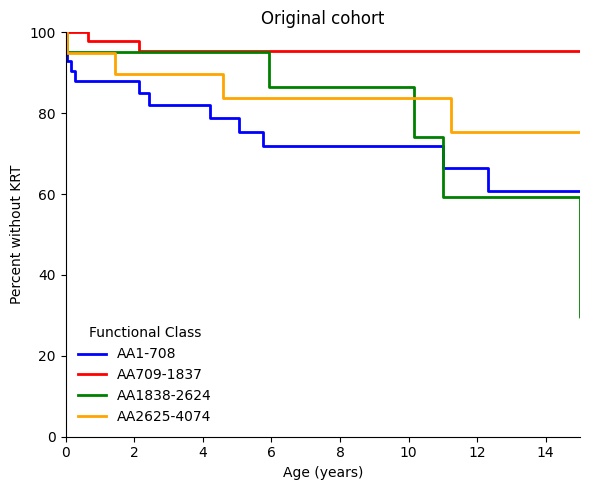

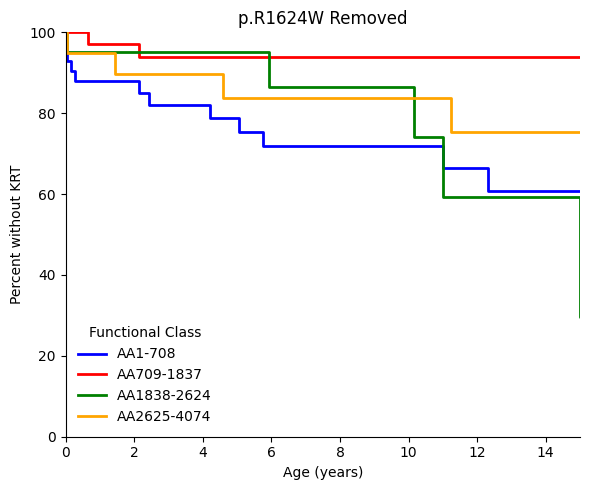

In [ ]:
# ==========================================================
# Function to create GraphPad-style KM plot
# ==========================================================

def plot_km(data, title):

    plt.figure(figsize=(6,5))

    for g in groups:

        gdf = data[data["Functional_Class"] == g].copy()

        if gdf.empty:
            continue

        gdf["time"] = gdf["KRT_age"].fillna(gdf["Last_followup_age"])
        gdf["event"] = gdf["KRT_age"].notna().astype(int)

        gdf = gdf.dropna(subset=["time"])

        kmf.fit(
            durations=gdf["time"],
            event_observed=gdf["event"],
            label=g
        )

        kmf.plot_survival_function(
            ci_show=False,
            color=color_map[g],
            linewidth=2
        )

    ax = plt.gca()

    # Titles and labels
    plt.title(title)
    plt.xlabel("Age (years)")
    plt.ylabel("Percent without KRT")

    # Axis limits
    plt.xlim(0,15)
    plt.ylim(0,1)

    # Convert to percent
    yticks = np.linspace(0,1,6)
    ax.set_yticks(yticks)
    ax.set_yticklabels((yticks*100).astype(int))

    # Clean GraphPad-like style
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.legend(title="Functional Class", frameon=False)

    plt.tight_layout()

    plt.show()


# ==========================================================
# Generate the two plots
# ==========================================================

plot_km(df, "Original cohort")

plot_km(df_no_R1624, "p.R1624W Removed")